NOTE: ORIGINAL .KINARM FILES + CSV FILES ARE TOO BIG TO UPLOAD TO GITHUB. A folder can be found in the **lab dropbox** under **projects -> sandbox -> dusty -> hayashi-data**

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
import json
import numpy as np
import matplotlib.ticker as ticker

from matplotlib.lines import Line2D
from collections import defaultdict

Constants and helpful values:

In [15]:
# These are the same colors as in the hayashi paper
color_map = {
    -45: '#91278f',
    -30: '#2e3092',
    -15: '#00aeef',
     0:  '#444444',
     15: '#f7931d',
     30: '#ed1c24',
     45: '#ec008c'
}

# Within Kinarm, the proprioceptive perturbation levels weren't defined in degrees (was based on the offset in cm from the directly forward path). 
# # This is the mapping from that measurement (in the dataset) to degrees.
mapping = {
    -5.77400016784668: (-30*-1), # -30 in our experiment, but flipped to match Hayashi 
    -2.6800000667572: (-15*-1),
    0.0: 0,
    2.6800000667572: (15*-1),
    5.77400016784668: (30*-1)
}

# I'm using the same system in order to flip the visual perturbation levels, so that they match with Hayashi
# In our program, rotations are in the CCW direction, but in Hayashi they are CW
mapping_vis = {
    -45: 45,
    -30: 30,
    -15: 15,
     0: 0,
     15: -15,
     30: -30,
     45: -45
}

# Helpful lists later
vis_pert_levels = [-45,-30, -15, 0, 15, 30, 45]
prop_pert_levels=[-30, -15, 0, 15, 30]
prop_pert_unmapped_levels = [-5.77400016784668, -2.6800000667572, 0.0, 2.6800000667572, 5.77400016784668]   

# Constants
SEC_TO_MS = 1000


# In some of the analysis figures from the Hayashi paper, they include force profile data before RT/ force onset.
# This number is somewhat arbitrary, but chosen to match their graphs.
BUFFER = 150;

Helper functions:

In [16]:
def json_decode(val):
    if isinstance(val, str):
        try:
            return json.loads(val)
        except (json.JSONDecodeError, TypeError):
            return val
    return val

def extract_subject_data(df):
    # Extracting data

    # Note about trial type: 1 = probe trial, 0= perturbation trial. 
    # We want to match the force profiles from the probe trials to the perturbation levels from the perturbation trials, which is why the trial types are different
    force_vals = df.loc[df['Trial Type'] == 1, 'Force X'].reset_index(drop=True)
    vis_vals   = df.loc[df['Trial Type'] == 0, 'Visual Pert'].reset_index(drop=True)
    prop_vals = df.loc[df['Trial Type'] == 0, 'Prop Pert'].reset_index(drop=True)

    # Using RT time to find the force onset
    onsets = (df.loc[df['Trial Type'] == 1, 'RTs'] * SEC_TO_MS).astype(int)
    # Extracting the peak velocity time and converting to MS
    peak_vels = (df.loc[df['Trial Type'] == 1, 'Time PV'] * SEC_TO_MS).astype(int)
    
    # To create figure 3A/B:

    aligned_forces = [
        force[onset-BUFFER:] 
        for force, onset in zip(force_vals, onsets)
    ]

    # Data for figure 3a
    forces_vis = list(zip(aligned_forces, vis_vals))
    # Data for figure 3b
    forces_prop = list(zip(aligned_forces, prop_vals))
    return forces_vis, forces_prop, onsets, peak_vels, aligned_forces, force_vals, vis_vals, prop_vals

def compute_subject_averages_visual(forces_vis):
    # Extracted the force profiles and visual perturbations from tuples to a dictionary for easier processing
    force_vis_dict = defaultdict(list)

    for force_array, vis_pert in forces_vis:
        force_vis_dict[vis_pert].append(force_array)
        
    # Compute mean force profile per perturbation level
    avg_forces = {}
    for vis_pert, forces_list in force_vis_dict.items():
            # Not all of the force profiles are the same length,
            # so I padded the shorter ones with NaNs to be able to take the average without biasing towards the shorter profiles
        max_len = max(len(force_array) for force_array in forces_list)
        padded = []
        for force_array in forces_list:
            pad_width = max_len - len(force_array)
            if pad_width > 0:
                force_array_padded = np.pad(force_array, (0, pad_width), constant_values=np.nan)
            else:
                force_array_padded = force_array
            padded.append(force_array_padded)
        padded = np.array(padded)
        avg_forces[vis_pert] = np.nanmean(padded, axis=0)
        
    return avg_forces

def compute_subject_averages_proprioceptive(forces_prop):
    # Extracted the force profiles and proprioceptive perturbations from tuples to a dictionary for easier processing
    force_prop_dict = defaultdict(list)

    for force_array, prop in forces_prop:
        # Convert proprioceptive perts to degrees from Kinarm format
        mapped_prop = mapping.get(prop, prop)
        force_prop_dict[mapped_prop].append(force_array)

    avg_forces = {}
    for prop_pert, force_list in force_prop_dict.items():
        # Same padding process as above to handle different length force profiles
        max_len = max(len(force_array) for force_array in force_list)
        padded = []
        for force_array in force_list:
            pad_width = max_len - len(force_array)
            if pad_width > 0:
                force_array_padded = np.pad(force_array, (0, pad_width), constant_values=np.nan)
            else:
                force_array_padded = force_array
            padded.append(force_array_padded)

        padded = np.array(padded)
        avg_forces[prop_pert] = np.nanmean(padded, axis=0)
    return avg_forces

Extracting data from csv:

In [17]:
file_path_s1 = "csv-files/dusty-hayashi.csv"
file_path_s2 = "csv-files/yoyo-hayashi.csv"

subject_files = [file_path_s1, file_path_s2]
subjects = len(subject_files)  

In [18]:
dfs = [pd.read_csv(file).map(json_decode) for file in subject_files]
df_1, df_2 = dfs

In [20]:
subject_averages = []
for df in dfs:
    force_vis, force_prop, onsets, peak_vels, aligned_forces, force_vals, vis_vals, prop_vals = extract_subject_data(df)
    avg_forces_vis = compute_subject_averages_visual(force_vis)
    avg_forces_prop = compute_subject_averages_proprioceptive(force_prop)
    
    # To create figure 3 C/D:

    # Set up force profiles for integration
    # This only goes from onset to peak velocity, rather than onset to end (which is what aligned_forces captures)
    int_forces = [
        force[onset:peak_vel] 
        for force, onset, peak_vel in zip(force_vals, onsets, peak_vels)
    ]
    # Based on the sampling rate of 1000 hz
    dt = 0.001

    # Integrate force profiles to get the after effects
    # Quantified by hayashi as "integrated lateral force from the force onset to the time of peak velocity"
    aftereffects = [np.trapezoid(segment, dx=dt) for segment in int_forces]
    
    subject_averages.append({
        'force_vis': force_vis,
        'force_prop': force_prop,
        'onsets': onsets,
        'peak_vels': peak_vels,
        'avg_forces_vis': avg_forces_vis,
        'avg_forces_prop': avg_forces_prop,
        'force_vals': force_vals,
        'vis_vals'  : vis_vals,
        'prop_vals' : prop_vals,
        'aftereffects': aftereffects
    })
    

**Figure 3A:** In the Hayashi paper, they don't include the 0° perturbation level, but I decided to include it here.

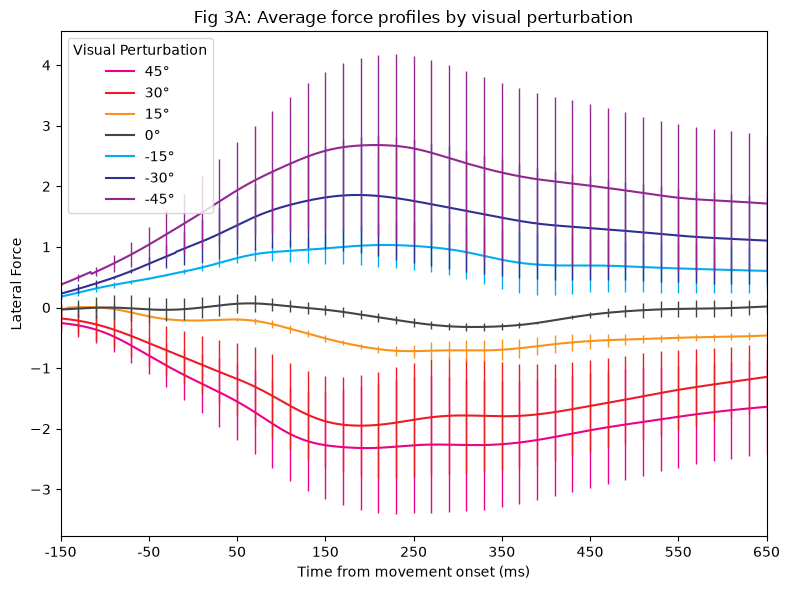

In [21]:
group_avg_forces = {}
group_sem_forces = {}

for visual_pert in vis_pert_levels:
    profiles = [
        np.array(sub['avg_forces_vis'][visual_pert])
        for sub in subject_averages
    ]
    
    # Find shortest length
    min_len = min(len(p) for p in profiles)
    
    # Trim all to same length
    trimmed = [p[:min_len] for p in profiles]
    
    stacked = np.vstack(trimmed)
    
    # Compute average force profile across subjects 
    group_avg = np.mean(stacked, axis=0)
    group_sem = np.std(stacked, axis=0) / np.sqrt(stacked.shape[0])
    
    group_avg_forces[visual_pert] = group_avg
    group_sem_forces[visual_pert] = group_sem

# ------------------- PLOTTING -------------------

plt.figure(figsize=(8, 6))
ax = plt.gca()

ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: int(x - BUFFER))
)
ax.set_xlim(left=0, right=800)

# How often to show error bars (avoid clutter)
error_step = 20  # adjust as needed

for vis_pert, avg_force_profile in group_avg_forces.items():
    # Flipping the sign of the graphed visual perturbation to match Hayashi 
    label = mapping_vis.get(vis_pert, str(vis_pert))
    color = color_map.get(label, None)
    sem = group_sem_forces[vis_pert]
    
    x = np.arange(len(avg_force_profile))
    
    # Plot mean line
    plt.plot(x, avg_force_profile, label=f'{label}°', color=color)
    
    # Plot error bars at intervals
    plt.errorbar(
        x[::error_step],
        avg_force_profile[::error_step],
        yerr=sem[::error_step],
        fmt='none',       
        ecolor=color,
        elinewidth=1,
        capsize=0
    )

plt.xlabel('Time from movement onset (ms)')
plt.ylabel('Lateral Force')
plt.legend(title="Visual Perturbation")
plt.title('Fig 3A: Average force profiles by visual perturbation')

plt.tight_layout()
plt.show()

**Figure 3B:** In the Hayashi paper, they don't include the 0° perturbation level, but I decided to include it here.

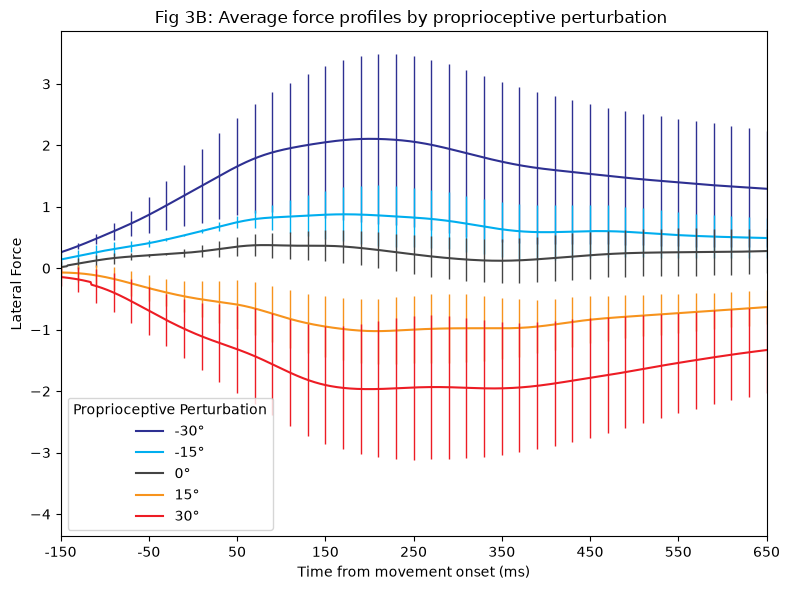

In [8]:
group_avg_forces = {}
group_sem_forces = {}

for prop_pert in prop_pert_levels:
    profiles = [
        np.array(sub['avg_forces_prop'][prop_pert])
        for sub in subject_averages
    ]
    
    # Find shortest length
    min_len = min(len(p) for p in profiles)
    
    # Trim all to same length
    trimmed = [p[:min_len] for p in profiles]
    
    stacked = np.vstack(trimmed)
    
    # Compute average force profile across subjects
    group_avg = np.mean(stacked, axis=0)
    group_sem = np.std(stacked, axis=0) / np.sqrt(stacked.shape[0])
    
    group_avg_forces[prop_pert] = group_avg
    group_sem_forces[prop_pert] = group_sem

# ------------------- PLOTTING -------------------

plt.figure(figsize=(8, 6))
ax = plt.gca()

ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: int(x - BUFFER))
)
ax.set_xlim(left=0, right=800)

# How often to show error bars (avoid clutter)
error_step = 20  # adjust as needed

for prop_pert, avg_force_profile in group_avg_forces.items():
    label = mapping.get(prop_pert, str(prop_pert))
    color = color_map.get(prop_pert, None)
    sem = group_sem_forces[prop_pert]
    
    x = np.arange(len(avg_force_profile))
    
    # Plot mean line
    plt.plot(x, avg_force_profile, label=f'{label}°', color=color)
    
    # Plot error bars at intervals
    plt.errorbar(
        x[::error_step],
        avg_force_profile[::error_step],
        yerr=sem[::error_step],
        fmt='none',       
        ecolor=color,
        elinewidth=1,
        capsize=0
    )

plt.xlabel('Time from movement onset (ms)')
plt.ylabel('Lateral Force')
plt.legend(title="Proprioceptive Perturbation")
plt.title('Fig 3B: Average force profiles by proprioceptive perturbation ')

plt.tight_layout()
plt.show()

**Figure 3C:**

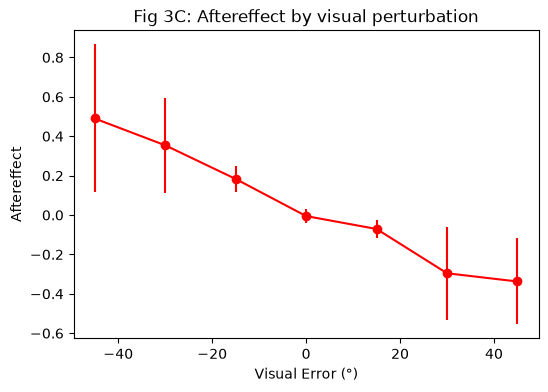

In [9]:
group_means = []
for sub in subject_averages:
    vis_vals = sub['vis_vals']
    aftereffects = sub['aftereffects']
    
    # Sort aftereffect by visual perturbation level
    force_arrays_by_visual_perturbation = {}
    for vis_pert, after_effect in zip(vis_vals, aftereffects):
        if vis_pert not in force_arrays_by_visual_perturbation:
            force_arrays_by_visual_perturbation[vis_pert] = []
        force_arrays_by_visual_perturbation[vis_pert].append(after_effect)

    # Calculate means and standard errors for error bars
    means = []
    for visual_pert in vis_pert_levels:
        forces_list = np.array(force_arrays_by_visual_perturbation[visual_pert])
        means.append(forces_list.mean())   
    group_means.append(means)

group_means = np.array(group_means)   
means = np.mean(group_means, axis=0)

# SEM across subjects
ses = np.std(group_means, axis=0, ddof=1) / np.sqrt(group_means.shape[0])

#Plotting
# Reversing the order is the same as flipping the signs of the visual perturbations (since perturbation levels are symmetric around 0)
means = means.tolist()
means.reverse() # Flip the order to match up with the CW Hayashi visual perturbation levels
ses = ses.tolist()
ses.reverse()

plt.figure(figsize=(6, 4))
plt.errorbar(vis_pert_levels, means, yerr=ses, fmt='o-', color='red', capsize=0)
plt.xlabel('Visual Error (°)')
plt.ylabel('Aftereffect')
plt.title('Fig 3C: Aftereffect by visual perturbation')
plt.show()
   

**Figure 3D:**

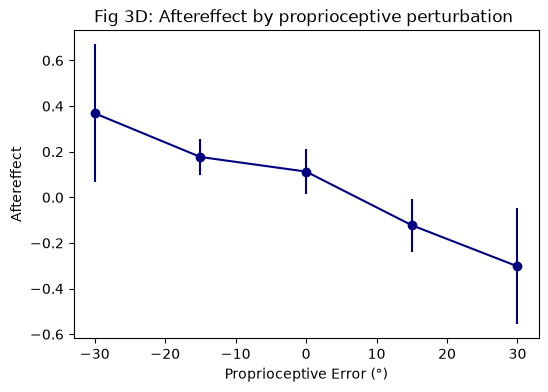

In [10]:
group_means = []
for sub in subject_averages:
    prop_vals = sub['prop_vals']
    aftereffects = sub['aftereffects']
    
    # Sort aftereffect by proprioceptive perturbation level
    force_arrays_by_proprioceptive_perturbation = {}
    for prop_pert, after_effect in zip(prop_vals, aftereffects):
        if prop_pert not in force_arrays_by_proprioceptive_perturbation:
            force_arrays_by_proprioceptive_perturbation[prop_pert] = []
        force_arrays_by_proprioceptive_perturbation[prop_pert].append(after_effect)

    # Calculate means and standard errors for error bars
    means = []
    for proprioceptive_pert in prop_pert_unmapped_levels:
        forces_list = np.array(force_arrays_by_proprioceptive_perturbation[proprioceptive_pert])
        means.append(forces_list.mean())   
    group_means.append(means)

group_means = np.array(group_means)   
     
means = np.mean(group_means, axis=0)

# SEM across subjects
ses = np.std(group_means, axis=0, ddof=1) / np.sqrt(group_means.shape[0])

#Plotting
plt.figure(figsize=(6, 4))
# Reversing the order is the same as flipping the signs of the visual perturbations (since perturbation levels are symmetric around 0)
means = means.tolist()
means.reverse() # Flip the order to match up with the CW Hayashi visual perturbation levels
ses = ses.tolist()
ses.reverse()

plt.errorbar(prop_pert_levels, means, yerr=ses, fmt='o-', color='navy', capsize=0)
plt.xlabel('Proprioceptive Error (°)')
plt.ylabel('Aftereffect')
plt.title('Fig 3D: Aftereffect by proprioceptive perturbation ')
plt.show()
   

**Figure 4A-E:**

To the best of my understanding, these figures are single subject data. Therefore, I decided not to include them in this notebook (you can find them in the single-subject notebook).

**Figure 4F:**

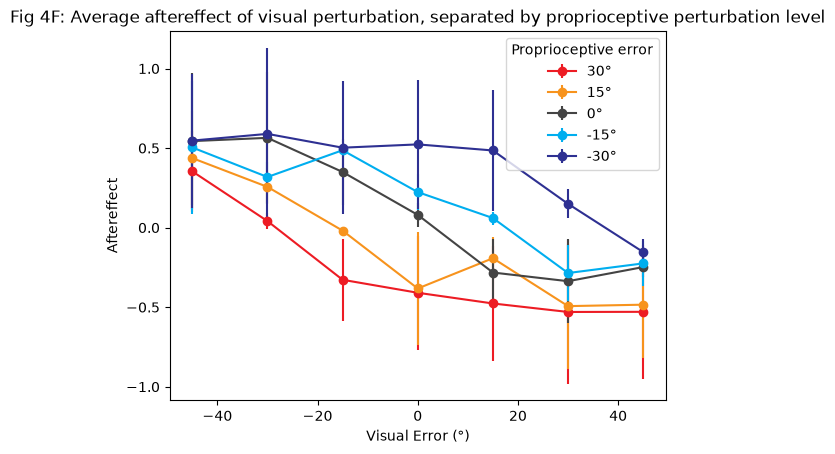

In [11]:
group_propxvis_matrix = []

for sub in subject_averages:
    # Extract per-subject data       
    vis_vals = sub['vis_vals']
    prop_vals = sub['prop_vals']
    aftereffects = sub['aftereffects']
    
    # Group after effect by proprioceptive level, then by visual perturbation
    grouped = defaultdict(lambda: defaultdict(list))
    for vis_pert, prop_pert, after in zip(vis_vals, prop_vals, aftereffects):
        grouped[prop_pert][vis_pert].append(after)
    
    # Build matrix (prop × vis) for each subject to keep proprioceptive and visual levels seperate 
    subject_means = []
    for prop_pert in prop_pert_unmapped_levels:
        row = []
        for vis_pert in vis_pert_levels:
            vals = grouped[prop_pert][vis_pert]
            row.append(np.mean(vals) if len(vals) > 0 else np.nan)
        # Each row contains the means for each prop x visual level combination  
        subject_means.append(row)
        
    # Append each subject's matrix to group, so that we can take the averages for each combination 
    group_propxvis_matrix.append(subject_means)

group_propxvis_matrix = np.array(group_propxvis_matrix)

# Calculate the mean and standard error for each proprioceptive x visual perturbation combination across subjects
means = np.nanmean(group_propxvis_matrix, axis=0)
ses = np.nanstd(group_propxvis_matrix, axis=0, ddof=1) / np.sqrt(group_propxvis_matrix.shape[0])


# Plotting
for i, prop_pert in enumerate(prop_pert_unmapped_levels):
    label = mapping.get(prop_pert, str(prop_pert))
    color = color_map.get(label, None)
    means_temp = means[i].tolist()
    # Reversing the order is the same as flipping the signs of the visual perturbations (since perturbation levels are symmetric around 0)
    means_temp.reverse() # Flip the order to match up with the CW Hayashi visual perturbation levels
    ses_temp = ses[i].tolist()
    ses_temp.reverse()
    plt.errorbar(vis_pert_levels, means_temp, yerr=ses_temp, fmt='o-', color= color, capsize=0, label=f'{label}°')
    

plt.xlabel('Visual Error (°)')
plt.ylabel('Aftereffect')
plt.title('Fig 4F: Average aftereffect of visual perturbation, separated by proprioceptive perturbation level')
plt.legend(title='Proprioceptive error')
plt.show()

**Figure 4G:**

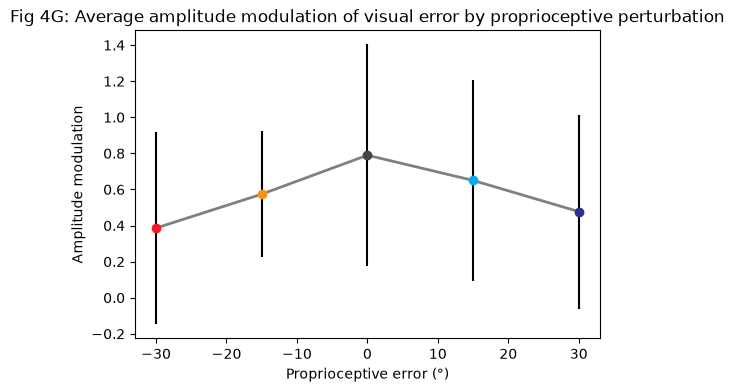

In [12]:
group_amps = []

for sub in subject_averages:
    # Extract per-subject data       
    vis_vals = sub['vis_vals']
    prop_vals = sub['prop_vals']
    aftereffects = sub['aftereffects']

    # Group after effect by proprioceptive level, then by visual perturbation
    grouped = defaultdict(lambda: defaultdict(list))
    for vis_pert, prop_pert, after in zip(vis_vals, prop_vals, aftereffects):
        grouped[prop_pert][vis_pert].append(after)

    subj_amp = []

    # For each prop level, calculate the amplidute modulation per subject
    for prop_pert in prop_pert_unmapped_levels:
        # Initialize empty arrays to hold aftereffects for pos and neg visual perturbations respectively
        pos_viserror_ae = []
        neg_viserror_ae = []

        for vis_pert in vis_pert_levels:
            data = grouped[prop_pert][vis_pert]

            if vis_pert > 0:
                pos_viserror_ae.extend(data)
            elif vis_pert < 0:
                neg_viserror_ae.extend(data)

        # Convert to numpy arrays for easier calculations 
        pos_viserror_ae  = np.array(pos_viserror_ae)
        neg_viserror_ae = np.array(neg_viserror_ae)

        # Calculate amp mod. by taking the difference between mean of after effects for positive and negative visual perturbations
        amp = pos_viserror_ae.mean() - neg_viserror_ae.mean()

        subj_amp.append(amp)
    # Append each sub's amp modulation to overall group array 
    group_amps.append(subj_amp)

# Find the group-level averages and error bars for the amp mod at prop pert level
group_amps = np.array(group_amps)
amp_means = np.nanmean(group_amps, axis=0)
amp_ses = np.nanstd(group_amps, axis=0, ddof=1) / np.sqrt(np.sum(group_amps, axis=0))

amp_means = amp_means.tolist()
# Reversing the order is the same as flipping the signs of the visual perturbations (since perturbation levels are symmetric around 0)
amp_means.reverse() # Flip the order to match up with the CW Hayashi

amp_ses = amp_ses.tolist()
amp_ses.reverse()

# Plotting
plt.figure(figsize=(6, 4))
for i, prop_pert in enumerate(prop_pert_levels):
    color = color_map.get(-prop_pert, None)
    plt.errorbar(prop_pert_levels[i], amp_means[i], yerr=amp_ses[i],
                 fmt='o-', color=color, ecolor='black', capsize=0)
plt.plot(prop_pert_levels, amp_means, color='gray', linewidth=2, zorder=0)

plt.xlabel('Proprioceptive error (°)')
plt.ylabel('Amplitude modulation')
plt.title('Fig 4G: Average amplitude modulation of visual error by proprioceptive perturbation')
plt.show()

**Figure 4H:**

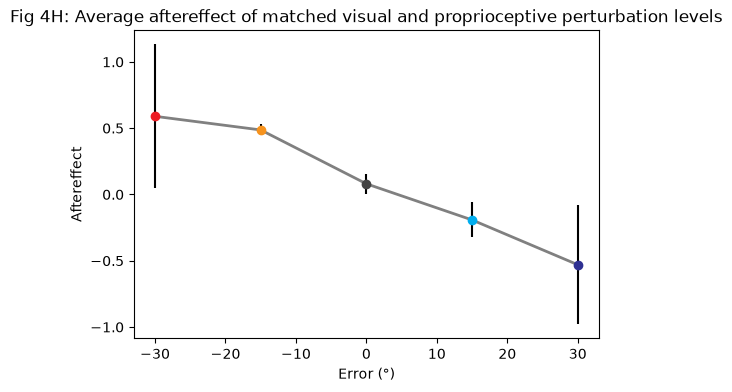

In [13]:
group_matched_errors = []

for sub in subject_averages:
    # Extract per-subject data       
    vis_vals = sub['vis_vals']
    prop_vals = sub['prop_vals']
    aftereffects = sub['aftereffects']

    # Convert the proprioceptive perturbation values to degrees using the mapping
    # Using prop_vals directly so they stay in the same trial order as the aftereffects and visual perturbations when we zip them together later
    prop_vals_deg = np.array([-1*mapping[p] for p in prop_vals])
    matched = {}
    # Sort and only extract the after effects on trials where visual and prop perts are equivalent 
    for vis, prop_deg, ae in zip(vis_vals, prop_vals_deg, aftereffects):
        if vis == prop_deg:
            if vis not in matched:
                matched[vis] = []
            matched[vis].append(ae)
            
    matched_levels = sorted(matched.keys())
    subj_means = []
    # For each subject and matching perturbation levels, calculate the mean of the after effect 
    for level in matched_levels:  
        data = np.array(matched[level])
        subj_means.append(np.mean(data))
        
    group_matched_errors.append(subj_means)

# Calculate group means and standard error
group_matched_errors = np.array(group_matched_errors)
means = np.nanmean(group_matched_errors, axis=0)
ses = np.nanstd(group_matched_errors, axis=0, ddof=1) / np.sqrt(np.sum(~np.isnan(group_matched_errors), axis=0))

means = means.tolist()
means.reverse() # Flip the order to match up with the CW Hayashi visual perturbation levels

ses = ses.tolist()
ses.reverse()

# Plotting
plt.figure(figsize=(6, 4))
for i, pert in enumerate(matched_levels):
    color = color_map.get(-pert, None)
    plt.errorbar(pert, means[i], yerr=ses[i],
                 fmt='o-', color=color, ecolor='black', capsize=0)
    
plt.plot(matched_levels, means, color='gray', linewidth=2, zorder=0)

plt.xlabel('Error (°)')
plt.ylabel('Aftereffect')
plt.title('Fig 4H: Average aftereffect of matched visual and proprioceptive perturbation levels')
plt.show()

